# A cantilever with a soft segment: vibration modes and finite elements

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 6, Section "A Priori Error Estimates", Example "A Cantilever with a Soft Segment".

The cantilever of the notebook `ch06_cantilever_modes`: unit length, clamped at $x = 0$, free at $x = 1$, uniform
load $p = 1$. Its bending stiffness is now $EI = 1$, except on the segment $0.4 < x < 0.6$, where it drops to
$EI = 0.7$ (a weakened or damaged region): a **jump** instead of the smooth dip of the previous notebook.
The Galerkin (Ritz) method minimizes
$$\mathcal{E}(w) = \int_0^1 \Big( \tfrac{1}{2}\, EI\, (w'')^2 - p\, w \Big)\, dx, \qquad w(0) = w'(0) = 0,$$
over the span of $N$ trial functions, by solving $\mathbf{K}\mathbf{U} = \mathbf{f}$ with
$K_{ij} = \int_0^1 EI\, \varphi_i''\varphi_j''\, dx$ and $f_i = \int_0^1 p\, \varphi_i\, dx$.

The beam is statically determinate: the bending moment is $M = \tfrac{1}{2}p(1-x)^2$ whatever the stiffness, and
the curvature $w'' = M/EI$ **jumps** at $x = 0.4$ and $x = 0.6$. The exact energy
$\mathcal{E}(w) = -\tfrac{1}{2}\int_0^1 M^2/EI\, dx$ is known, and the relative error in the energy norm follows
from the energy of the approximation alone:
$$\frac{\|w - w_h\|_a}{\|w\|_a} = \sqrt{\frac{\mathcal{E}(w_h) - \mathcal{E}(w)}{-\mathcal{E}(w)}} .$$

Two bases:
1. the vibration modes of the **uniform** cantilever, the same functions of `ch06_cantilever_modes`;
2. the Hermite cubic finite elements on a uniform mesh, two unknowns per node, either with nodes at the two jumps
   of the stiffness ($N_e$ a multiple of 5) or with nodes elsewhere.

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell and run everything again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ---------------------------------------------------------------- PARAMETERS
EI_soft  = 0.7               # stiffness of the soft segment (EI = 1 elsewhere); 1.0 = uniform beam
x1, x2   = 0.4, 0.6          # ends of the soft segment
p        = 1.0               # uniform load
N_modes  = [1, 2, 4, 6, 8, 10, 16, 20, 32, 40, 64, 80]   # numbers of vibration modes
Ne_al    = [5, 10, 15, 20, 30]   # Hermite elements with nodes at x1, x2 (N = 2 Ne unknowns)
Ne_nal   = [3, 6, 12, 24, 48]    # Hermite elements with nodes elsewhere
N_show   = 10                # number of unknowns of the approximations plotted
# ---------------------------------------------------------------------------

## 1. Ingredients

Every integral is computed with Gauss–Legendre quadrature on a subdivision of $(0, 1)$ into 1200 equal
intervals: the jumps of the stiffness and the nodes of every mesh used below fall on interval ends, so piecewise
smooth integrands are integrated to round-off. Each basis function is stored through its values and curvatures
at the quadrature points, which is all that $\mathbf{K}$ and $\mathbf{f}$ need. Besides the error we compute the
condition number of $\mathbf{K}$ after a diagonal scaling, $\mathbf{D}^{-1/2}\mathbf{K}\mathbf{D}^{-1/2}$ with
$\mathbf{D} = \mathrm{diag}(\mathbf{K})$, which is what we get by normalizing every basis function in energy.

In [2]:
def quadrature(nq, n=8):
    """Gauss-Legendre points and weights on (0,1) divided into nq equal intervals."""
    g, wg = np.polynomial.legendre.leggauss(n)
    return (np.concatenate([(e + (g + 1) / 2) / nq for e in range(nq)]),
            np.concatenate([wg / 2 / nq] * nq))

EI = lambda x: np.where((x > x1) & (x < x2), EI_soft, 1.0)
xq, wq = quadrature(1200)
E_exact = -0.5 * np.sum(wq * (0.5 * p * (1 - xq)**2)**2 / EI(xq))

def galerkin(phi, d2):
    """phi, d2: arrays (N, number of points) with the basis functions and their curvatures."""
    K = (d2 * EI(xq) * wq) @ d2.T
    f = (phi * p) @ wq
    U = np.linalg.solve(K, f)
    E = -0.5 * U @ f                                   # energy at the minimum = -1/2 (work of the load)
    err = np.sqrt(max(E - E_exact, 0.0) / -E_exact)    # round-off can make E - E_exact slightly negative
    d = 1 / np.sqrt(np.diag(K))
    return err, np.linalg.cond(K * d[:, None] * d[None, :]), U

print(f"exact energy = {E_exact:.10f}")

exact energy = -0.0257234286


## 2. The two bases

**Vibration modes of the uniform cantilever.** $\varphi_k'''' = \mu_k^4\varphi_k$, clamped at $x = 0$, free at
$x = 1$, with $1 + \cos\mu_k\cosh\mu_k = 0$ and
$\varphi_k = \cosh\mu_k x - \cos\mu_k x - \sigma_k(\sinh\mu_k x - \sin\mu_k x)$; the hyperbolic part is written with
decaying exponentials, as in `ch06_cantilever_modes`. They know nothing about the soft segment.

**Hermite cubics.** On each element of length $h$, with $s = (x - x_e)/h$, the four shape functions
$$N_1 = 1 - 3s^2 + 2s^3,\quad N_2 = h(s - 2s^2 + s^3),\quad N_3 = 3s^2 - 2s^3,\quad N_4 = h(s^3 - s^2)$$
multiply the displacement and the rotation at the left node and at the right node. The clamp removes the two
unknowns of the node $x = 0$.

In [3]:
mu = np.array([brentq(lambda m: 1 + np.cos(m) * np.cosh(m), a - 0.6, a + 0.6)
               for a in (np.arange(1, 101) - 0.5) * np.pi])
den = np.cosh(mu) + np.cos(mu)
sg, smn = (np.sinh(mu) - np.sin(mu)) / den, (np.exp(-mu) + np.cos(mu) + np.sin(mu)) / den   # sigma, 1 - sigma

def modes(N, x):
    m, s, s1 = mu[:N, None], sg[:N, None], smn[:N, None]
    ep, em = s1 * np.exp(m * x) / 2, (1 + s) * np.exp(-m * x) / 2
    c, sn = np.cos(m * x), np.sin(m * x)
    return ep + em - c + s * sn, m**2 * (ep + em + c - s * sn)

def hermite(Ne, x):
    h = 1 / Ne
    e = np.minimum((x / h).astype(int), Ne - 1); s = x / h - e
    shapes = [1 - 3*s**2 + 2*s**3, h*(s - 2*s**2 + s**3), 3*s**2 - 2*s**3, h*(s**3 - s**2)]
    curv   = [(-6 + 12*s) / h**2, (-4 + 6*s) / h, (6 - 12*s) / h**2, (6*s - 2) / h]
    out = [np.zeros((2 * (Ne + 1), x.size)) for _ in range(2)]; cols = np.arange(x.size)
    for j in range(4):
        for o, v in zip(out, (shapes, curv)):
            np.add.at(o, (2 * e + j, cols), v[j])
    return [o[2:] for o in out]     # drop displacement and rotation of the clamped node

## 3. Error and conditioning


modes
   N   energy error   kappa(scaled K)
   1     8.48e-02    1.00e+00
   2     7.85e-02    1.13e+00
   4     5.54e-02    1.30e+00
   6     4.20e-02    1.39e+00
   8     3.50e-02    1.43e+00
  10     3.31e-02    1.45e+00
  16     2.63e-02    1.48e+00
  20     2.38e-02    1.49e+00
  32     1.93e-02    1.49e+00
  40     1.70e-02    1.49e+00
  64     1.36e-02    1.49e+00
  80     1.20e-02    1.49e+00

Hermite, nodes at jumps
   N   energy error   kappa(scaled K)
  10     6.85e-03    3.64e+03
  20     1.71e-03    5.41e+04
  30     7.61e-04    2.70e+05
  40     4.28e-04    8.51e+05
  60     1.90e-04    4.29e+06

Hermite, other nodes
   N   energy error   kappa(scaled K)
   6     5.93e-02    5.62e+02
  12     3.54e-02    7.33e+03
  24     2.84e-02    1.11e+05
  48     1.84e-02    1.76e+06
  96     1.39e-02    2.81e+07


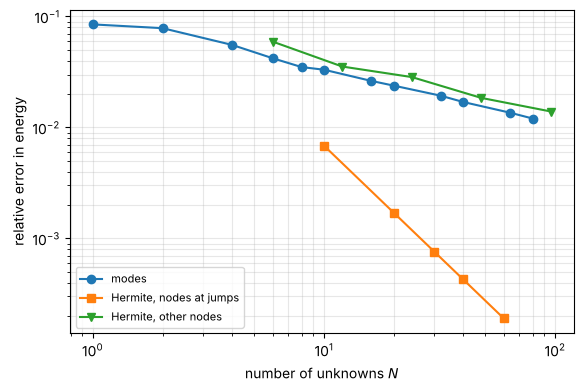

In [4]:
run = lambda basis, n: galerkin(*basis(n, xq))[:2]
res = {"modes":                   [(N, *run(modes, N)) for N in N_modes],
       "Hermite, nodes at jumps": [(2 * Ne, *run(hermite, Ne)) for Ne in Ne_al],
       "Hermite, other nodes":    [(2 * Ne, *run(hermite, Ne)) for Ne in Ne_nal]}
for name, rows in res.items():
    print(f"\n{name}\n   N   energy error   kappa(scaled K)")
    for N, err, ks in rows:
        print(f"{N:4d}   {err:10.2e}   {ks:9.2e}")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for (name, rows), m in zip(res.items(), "osv"):
    N, err, ks = np.array(rows).T
    ax.loglog(N, err, m + "-", label=name)
ax.set_xlabel("number of unknowns $N$"); ax.set_ylabel("relative error in energy")
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
plt.show()

* The **modes of the uniform cantilever**, which converged like $n^{-2.5}$ for the smooth dip of
  `ch06_cantilever_modes`, now converge like $N^{-1/2}$: they are smooth functions, and no finite combination of
  them can follow a jump of the curvature. They remain perfectly conditioned: $\mathbf{K}$ is almost diagonal.
* **Hermite elements with nodes at the jumps** converge like $h^2 \sim N^{-2}$, as for a smooth stiffness: inside
  each element the solution is smooth, and the error estimates apply element by element.
* **The same elements with nodes elsewhere** drop to $N^{-1/2}$, like the modes: an element that contains a jump of
  the curvature must approximate it with a cubic.

The condition number of the finite element matrices grows like $N^4$, whatever the scaling: the fourth-order
operator represents, on a mesh of size $h$, wavelengths as short as $h$, with stiffness of order $h^{-4}$.

## 4. Curvature and bending moment

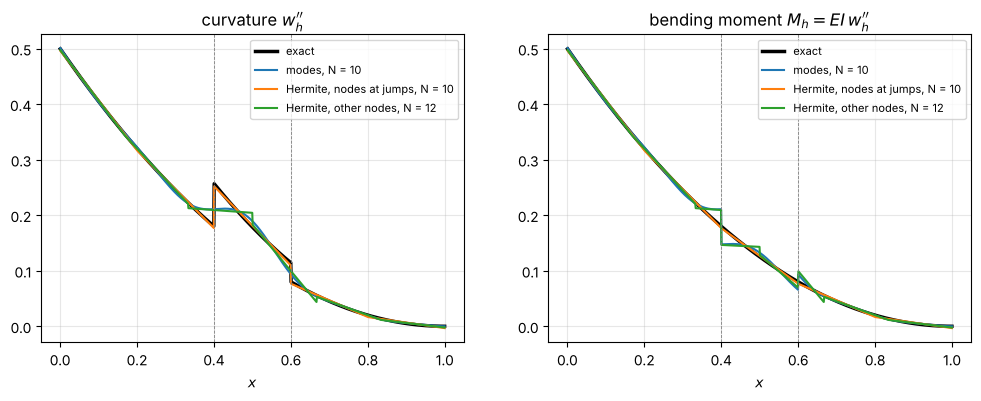

In [5]:
xs = (np.arange(1000) + 0.5) / 1000          # plotting points, never exactly on a node or a jump
M_ex = 0.5 * p * (1 - xs)**2
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(xs, M_ex / EI(xs), "k", lw=2.5, label="exact"); a2.plot(xs, M_ex, "k", lw=2.5, label="exact")
for name, basis, n in [("modes", modes, N_show), ("Hermite, nodes at jumps", hermite, N_show // 2),
                       ("Hermite, other nodes", hermite, N_show // 2 + 1)]:
    U = galerkin(*basis(n, xq))[2]
    d2 = basis(n, xs)[1]
    a1.plot(xs, U @ d2, label=f"{name}, N = {len(U)}")
    a2.plot(xs, EI(xs) * (U @ d2), label=f"{name}, N = {len(U)}")
a1.set_title("curvature $w_h''$"); a2.set_title("bending moment $M_h = EI\\, w_h''$")
for a in (a1, a2):
    a.set_xlabel("$x$"); a.grid(alpha=0.3); a.legend(fontsize=8)
    for xj in (x1, x2): a.axvline(xj, color="gray", lw=0.6, ls="--")
plt.show()

The modes smear the jumps of the curvature over the whole beam, and their bending moment jumps where the exact one
is continuous. The Hermite elements with nodes at $x = 0.4$ and $0.6$ follow the jumps exactly.

A closer look at them. Their **nodal displacements and rotations are exact**: $EI$ is constant on each element, the
exact solution is a quartic there, and the argument of Section 6.3.1 applies. The bending moment $M_h = EI\, w_h''$
is linear on each element, and differs from the exact parabola by $-p h^2/12$ at the nodes and $+p h^2/24$ at the
midpoints, whatever the stiffness; it is exact at the two Gauss points of each element,
$s = \tfrac{1}{2} \pm \tfrac{1}{2\sqrt{3}}$.

M_h - M at the nodes (left limits): [-0.003333 -0.003333 -0.003333 -0.003333 -0.003333 -0.003333]   -p h^2/12 = -0.003333
max |M_h - M| at the Gauss points: 1.7263968032921184e-13


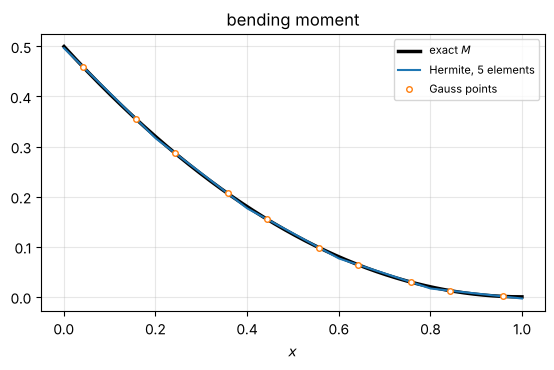

In [6]:
Ne = Ne_al[0]; h = 1 / Ne
U = galerkin(*hermite(Ne, xq))[2]
xn = np.arange(Ne + 1) * h
Mh_nodes = [EI(np.array([xn[i] - 1e-9 if i else 1e-9]))[0] * (U @ hermite(Ne, np.array([xn[i] - 1e-9 if i else 1e-9]))[1])[0]
            for i in range(Ne + 1)]
print("M_h - M at the nodes (left limits):", np.round(np.array(Mh_nodes) - 0.5 * p * (1 - xn)**2, 6),
      f"  -p h^2/12 = {-p * h**2 / 12:.6f}")
gp = (np.arange(Ne)[:, None] + 0.5 + np.array([-1, 1]) / (2 * np.sqrt(3))).ravel() * h
print("max |M_h - M| at the Gauss points:", np.abs(EI(gp) * (U @ hermite(Ne, gp)[1]) - 0.5 * p * (1 - gp)**2).max())

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(xs, M_ex, "k", lw=2.5, label="exact $M$")
ax.plot(xs, EI(xs) * (U @ hermite(Ne, xs)[1]), label=f"Hermite, {Ne} elements")
ax.plot(gp, 0.5 * p * (1 - gp)**2, "o", ms=4, mfc="w", label="Gauss points")
ax.set_xlabel("$x$"); ax.set_title("bending moment"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

## Things to try
1. Set `EI_soft = 1.0` (uniform beam): the modes diagonalize $\mathbf{K}$ exactly, and the Hermite elements give the
   exact energy up to the $h^4$ error of the cubic interpolation of a quartic.
2. Make the soft segment much softer, `EI_soft = 0.1`: does the rate of convergence change, or only the constant?
3. Move the soft segment to `x1, x2 = 0.33, 0.5` and check which meshes now have nodes at the jumps.
4. **Modes that know about the jumps.** Compute the vibration modes of the *actual* beam numerically: assemble, on a
   mesh of 40 elements (nodes at the jumps), the Hermite stiffness matrix $\mathbf{K}$ and the consistent mass matrix
   $\mathbf{M}$, with $M_{ij} = \int_0^1 N_i N_j\, dx$, and solve $\mathbf{K}\boldsymbol{\Phi} = \lambda\mathbf{M}\boldsymbol{\Phi}$
   (`scipy.linalg.eigh(K, M)`). Use the first $n$ modes as a basis: $\mathbf{K}$ is diagonal again, and the error
   decreases like $n^{-5/2}$, as for the smooth stiffness of `ch06_cantilever_modes`, down to the error of that mesh,
   about $10^{-4}$ (on much finer meshes round-off in the eigenvalue solver sets the floor earlier). The curvature of every such mode jumps at $x = 0.4$ and $0.6$, as the exact one does. The difficulty was
   never "modes against elements", but whether the basis knows where the data are rough.